Fine-tune gradient boosting models (LightGBM, CatBoost, XGBoost) by optimizing learning rates, regularization parameters, and tree structures, ensuring robust generalization across validation folds.

In [1]:
import pandas as pd
import numpy as np

In [2]:
np.random.seed(42)

In [3]:
n_samples = 1000

In [4]:
age = np.random.normal(62, 12, n_samples).clip(25, 90)
sofa_score = np.random.poisson(lam=4, size=n_samples).clip(0, 15)
lactate = np.random.exponential(scale=2.0, size=n_samples).round(2)
creatinine = np.random.normal(1.4, 0.6, n_samples).clip(0.5, 5.0).round(2)
platelets = np.random.normal(220, 75, n_samples).clip(20, 550).round(1)

In [5]:
risk_logits = (
    0.03 * (age - 62)
    + 0.35 * sofa_score
    + 0.4 * lactate
    + 0.5 * (creatinine - 1.4)
    - 0.008 * (platelets - 220)
    + 0.08 * sofa_score * lactate # Non-linear interaction
    - 3.2
)

In [6]:
probs = 1 / (1 + np.exp(-risk_logits))
target = (probs > np.median(probs)).astype(int)

In [7]:
df_gb = pd.DataFrame({
    'age': age.round(1),
    'sofa_score': sofa_score,
    'lactate': lactate,
    'creatinine': creatinine,
    'platelets': platelets,
    'high_risk': target
})

In [8]:
print("Dataset Shape:", df_gb.shape)
print("Target Distribution:\n", df_gb['high_risk'].value_counts())

Dataset Shape: (1000, 6)
Target Distribution:
 high_risk
0    500
1    500
Name: count, dtype: int64


In [9]:
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import HistGradientBoostingClassifier

In [10]:
X = df_gb.drop(columns=['high_risk'])
y = df_gb['high_risk']


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

In [12]:
hgb_param_dist = {
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'max_iter': [100, 200, 300],
    'max_leaf_nodes': [15, 31, 63],
    'min_samples_leaf': [10, 20, 40],
    'l2_regularization': [0.0, 0.1, 1.0, 5.0, 10.0]
}

In [13]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [14]:
hgb_search = RandomizedSearchCV(
    estimator=HistGradientBoostingClassifier(early_stopping=True, random_state=42),
    param_distributions=hgb_param_dist,
    n_iter=20,
    scoring='f1',
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1
)

In [15]:
hgb_search.fit(X_train, y_train)
best_hgb = hgb_search.best_estimator_

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

In [16]:
print("Best Parameters:", hgb_search.best_params_)
print(f"Best 5-Fold Stratified CV F1-Score: {hgb_search.best_score_:.4f}")

Best Parameters: {'min_samples_leaf': 40, 'max_leaf_nodes': 15, 'max_iter': 300, 'learning_rate': 0.1, 'l2_regularization': 0.0}
Best 5-Fold Stratified CV F1-Score: 0.9461


In [17]:
import xgboost as xgb

In [18]:
xgb_param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 6],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.7, 0.85, 1.0],
    'colsample_bytree': [0.7, 0.85, 1.0],
    'reg_alpha': [0.0, 0.1, 1.0, 5.0],    # L1 Regularization
    'reg_lambda': [0.1, 1.0, 5.0, 10.0]   # L2 Regularization
}

In [19]:
xgb_search = RandomizedSearchCV(
    estimator=xgb.XGBClassifier(eval_metric='logloss', random_state=42),
    param_distributions=xgb_param_dist,
    n_iter=20,
    scoring='f1',
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1
)

In [20]:
xgb_search.fit(X_train, y_train)
best_xgb = xgb_search.best_estimator_

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:528: FitFailedWarning: 
3 fits failed out of a total of 100.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1 fits failed with the following error:
Traceback (most recent call last):
  File "c:\ProgramData\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\rutva\AppData\Roaming\Python\Python313\site-packages\xgboost\core.py", line 569, in inner_f
    return func(**kwargs)
  File "C:\Users\rutva\AppData\Roaming\Python\Python313\site-packages\xgboost\sklearn.py", line 1838, in fit
    train_dmatrix

In [21]:
print("Best Parameters:", xgb_search.best_params_)
print(f"Best 5-Fold Stratified CV F1-Score: {xgb_search.best_score_:.4f}")

Best Parameters: {'subsample': 0.7, 'reg_lambda': 0.1, 'reg_alpha': 5.0, 'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 0.85}
Best 5-Fold Stratified CV F1-Score: 0.9463


In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, average_precision_score

In [23]:
models = {
    'HistGradientBoosting (Sklearn)': best_hgb,
    'XGBoost (Tuned)': best_xgb
}

In [24]:
benchmark_data = []

In [25]:
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    benchmark_data.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
        'PR-AUC': average_precision_score(y_test, y_proba)
    })

In [26]:
df_gb_metrics = pd.DataFrame(benchmark_data).set_index('Model')
print("--- Holdout Test Performance Comparison ---")
print(df_gb_metrics.round(4))

--- Holdout Test Performance Comparison ---
                                Accuracy  F1-Score  ROC-AUC  PR-AUC
Model                                                              
HistGradientBoosting (Sklearn)     0.920    0.9174   0.9871  0.9872
XGBoost (Tuned)                    0.932    0.9312   0.9913  0.9914


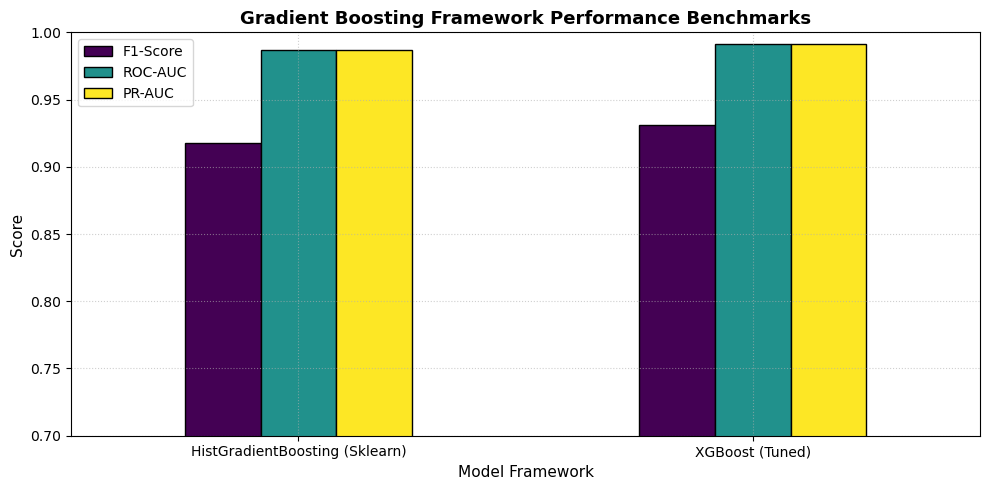

In [27]:
fig, ax = plt.subplots(figsize=(10, 5))
df_gb_metrics[['F1-Score', 'ROC-AUC', 'PR-AUC']].plot(
    kind='bar', 
    ax=ax, 
    colormap='viridis', 
    edgecolor='black'
)

ax.set_title("Gradient Boosting Framework Performance Benchmarks", fontsize=13, fontweight='bold')
ax.set_ylabel("Score", fontsize=11)
ax.set_xlabel("Model Framework", fontsize=11)
ax.set_ylim(0.7, 1.0)
plt.xticks(rotation=0)
ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()